# Data analysis: SVR voicemail dataset

## Contents
1. Dataset overview
1b. Data type differences across sources
2. Audio quality
3. Transcripts
4. Duplicates
5. Labels (version 1)
6. Issues detected
7. Insights

Scope: the full SVR dataset, 6,522 audio files and 6,024 transcripts. This notebook states what the data is, what is wrong with it, and what we learned. It is the analysis that drives the preprocessing and labeling notebooks. Every number below is computed from the source files in this run, not copied from a report.

In [1]:
import json, os
import pandas as pd
from pathlib import Path
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

WS = Path("/home/hatch/workspace/ai-customer-support")
REPO = WS / "smart-voicemail-router"
PREPARED = WS / "dataset" / "prepared"
PREPROCESSED = WS / "dataset" / "preprocessed"
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

def save_fig(fig, fname):
    path = FIGDIR / fname
    FigureCanvasAgg(fig).print_png(str(path))
    return path

def show(fname):
    display(Image(str(FIGDIR / fname)))

def bar(values, labels, title, ylabel, fname, color="#2f6fb2", horizontal=False):
    fig = Figure(figsize=(8, 4.6))
    ax = fig.add_subplot(111)
    if horizontal:
        ax.barh(labels, values, color=color)
        ax.set_title(title)
        ax.set_xlabel(ylabel)
    else:
        ax.bar(labels, values, color=color)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

def hist(data, title, xlabel, ylabel, fname, bins=30, color="#2f6fb2"):
    fig = Figure(figsize=(8, 4.2))
    ax = fig.add_subplot(111)
    ax.hist(data, bins=bins, color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

inv = json.loads((WS / "dataset" / "audio_inventory.json").read_text(encoding="utf-8"))
eda = json.loads((REPO / "eda" / "eda_summary.json").read_text(encoding="utf-8"))
prep = json.loads((REPO / "preprocessing" / "preprocessing_summary.json").read_text(encoding="utf-8"))
audit = json.loads((PREPARED / "audit_summary.json").read_text(encoding="utf-8"))
clean = pd.read_csv(PREPROCESSED / "transcripts_clean.csv")
lab = pd.read_csv(PREPARED / "labeled_full_v1.csv")
lab_sum = json.loads((PREPARED / "labeling_summary.json").read_text(encoding="utf-8"))
other_themes = json.loads((PREPARED / "other_themes.json").read_text(encoding="utf-8"))
quar = pd.read_csv(PREPARED / "quarantine_decisions.csv")
excl = json.loads((PREPARED / "excluded_verification.json").read_text(encoding="utf-8"))
print("loaded:", len(inv["files"]), "inventory files,", len(clean), "clean transcripts,", len(lab), "labeled rows")
print("pandas", pd.__version__)

loaded: 6522 inventory files, 6024 clean transcripts, 5881 labeled rows
pandas 2.1.4


## 1. Dataset overview

Single speaker Egyptian Arabic voicemail, including English telecom terms. The archive holds 6,522 audio files. 6,024 of them have a Whisper large-v3 transcript. The rest have no transcript row: they are the excluded files (mostly duplicates) plus a small remainder.

In [2]:
a = inv["aggregate"]
print("total files:", a["total_files"])
print("total duration:", round(a["total_duration_h"], 2), "hours")
print("duration mean:", a["duration_stats"]["mean_s"], "s, median:", a["duration_stats"]["median_s"], "s")
print("duration range:", a["duration_stats"]["min_s"], "to", a["duration_stats"]["max_s"], "s")
print("sample rates:", a["sample_rates"])
print("channels:", a["channels"])
print("codecs:", a["codecs"])
print("unreadable files:", a["unreadable_count"])
print()
print("formats:")
for k, v in sorted(a["formats"].items(), key=lambda kv: -kv[1]):
    print(" ", k, v)
print()
print("duration buckets:")
for k, v in a["duration_histogram"].items():
    print(" ", k, v)
print()
print("Five real inventory rows (file, format, duration, sample rate, channels):")
for f in inv["files"][:5]:
    print(" ", f["file"], "|", f["ext"], "|", round(f["duration_s"], 2), "s |", f["sample_rate"], "Hz |", f["channels"], "ch")

total files: 6522
total duration: 12.63 hours
duration mean: 6.972 s, median: 6.208 s
duration range: 0.41 to 125.922 s
sample rates: {'44100': 1052, '48000': 5470}
channels: {'1': 3709, '2': 2813}
codecs: {'aac': 4165, 'mp3': 1177, 'opus': 1157, 'pcm_s24le': 23}
unreadable files: 0

formats:
  .m4a 2012
  .mp4 1656
  .ogg 1039
  .mpeg 723
  .aac 579
  .mp3 472
  .wav 23
  .opus 13
  .ogx 5

duration buckets:
  0-2s 4
  2-4s 415
  4-6s 2532
  6-8s 2028
  8-10s 752
  10-15s 633
  15-30s 157
  30-60s 0
  60s+ 1

Five real inventory rows (file, format, duration, sample rate, channels):
  الكل ان شاء الله/0001.m4a | .m4a | 7.53 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0002.m4a | .m4a | 7.87 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0003.m4a | .m4a | 23.91 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0004.m4a | .m4a | 7.68 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0006.m4a | .m4a | 4.76 s | 48000 Hz | 1 ch


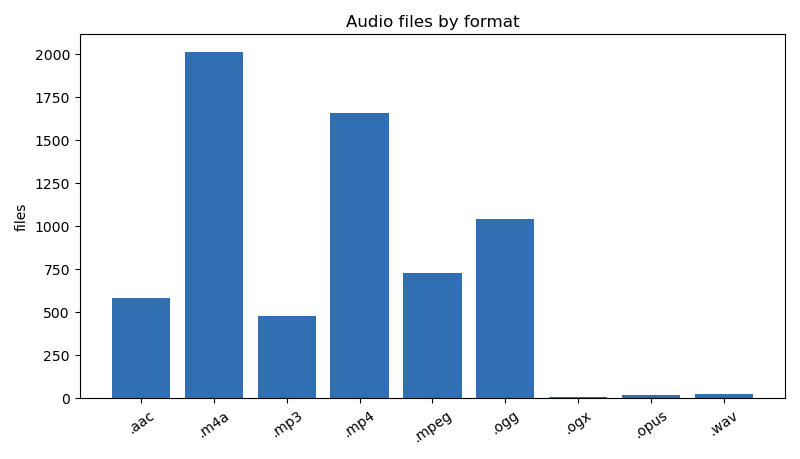

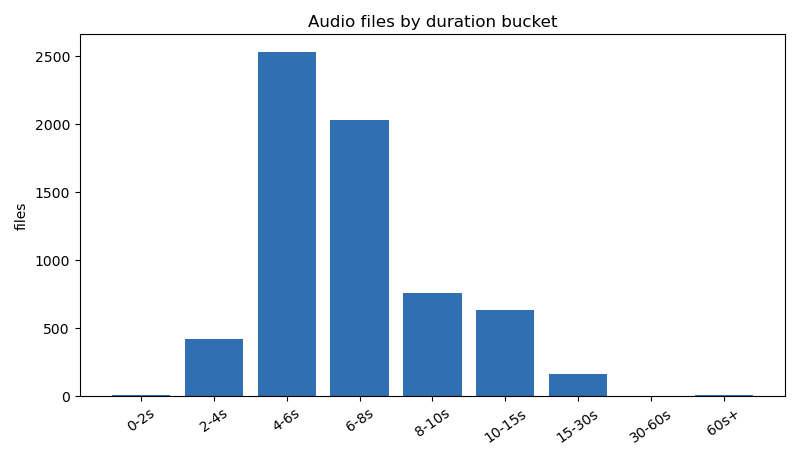

In [3]:
# Charts: format mix and duration buckets
fmt = inv["aggregate"]["formats"]
bar(list(fmt.values()), list(fmt.keys()), "Audio files by format", "files", "formats.png")
dur = inv["aggregate"]["duration_histogram"]
bar(list(dur.values()), list(dur.keys()), "Audio files by duration bucket", "files", "duration_buckets.png")

In [4]:
# Per format handling: each source type handled on its own terms
rows = []
for ext in sorted(inv["aggregate"]["formats"].keys()):
    fs = [f for f in inv["files"] if f["ext"] == ext]
    durs = [f["duration_s"] for f in fs]
    srs = sorted(set(f["sample_rate"] for f in fs))
    chs = sorted(set(f["channels"] for f in fs))
    codecs = sorted(set(f["codec"] for f in fs))
    drift = prep["details"]["drift_vs_inventory"]["by_format"].get(ext, 0)
    rows.append({"format": ext, "files": len(fs), "codec": ",".join(codecs),
                 "sample_rates": ",".join(str(s) for s in srs),
                 "channels": ",".join(str(c) for c in chs),
                 "mean_duration_s": round(sum(durs) / len(durs), 2),
                 "drift_over_0.1s": drift})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("Handling: every format is decoded to 16 kHz mono WAV before any model sees it.")
print("The .aac drift (79 files) comes from raw ADTS headers; the decoded PCM duration is the truth.")
print("The .mp4 files are audio in a video container; only the audio stream is used.")

format  files     codec sample_rates channels  mean_duration_s  drift_over_0.1s
  .aac    579       aac  44100,48000      1,2             7.08               79
  .m4a   2012  aac,opus  44100,48000      1,2             6.89                3
  .mp3    472   aac,mp3  44100,48000        2             7.51                0
  .mp4   1656       aac  44100,48000      1,2             7.40                0
 .mpeg    723       mp3  44100,48000      1,2             6.17                0
  .ogg   1039      opus        48000        1             6.66                0
  .ogx      5      opus        48000        1             9.06                0
 .opus     13      opus        48000        1             9.13                0
  .wav     23 pcm_s24le        48000        2             7.64                0

Handling: every format is decoded to 16 kHz mono WAV before any model sees it.
The .aac drift (79 files) comes from raw ADTS headers; the decoded PCM duration is the truth.
The .mp4 files are audio i

## 1b. Data type differences across sources

The data was collected from different sources, so the files arrive in different types. This is not a defect in one file, it is the shape of the whole dataset, and any step that touches the audio must handle it.

File formats (6,522 files): m4a 2,012, mp4 1,656, ogg 1,039, mpeg 723, aac 579, mp3 472, wav 23, opus 13, ogx 5. Nine formats in total. The two biggest, m4a and mp4, are just over half the files. The long tail (wav, opus, ogx) is 41 files.

Sample rates: 48 kHz on 5,470 files, 44.1 kHz on 1,052 files. Two rates, no other rate in the set.

Channels: mono 3,709 files, stereo 2,813 files. More than 4 in 10 files are stereo.

Insight: no single format, rate, or channel count can be assumed. A pipeline that expects one type would fail on most of the data, and a model trained on one type would see a different distribution at run time. The fix is to decode every file to one standard type, 16 kHz mono WAV, before any model sees it, and to measure quality on the decoded audio, not on file headers. Two traps live in the types: raw .aac (ADTS) headers give a wrong duration (79 files drift over 0.1 seconds), and .mp4 is a video container whose audio stream is the only part used. The per format table above shows each type handled on its own terms.

## 2. Audio quality

Quality was measured on the decoded audio, not on file headers. Three flags matter: clipping (samples at full scale), silence share, and signal to noise ratio. Clipping is the biggest group but almost all of it is tiny, under 1 percent of samples, which is why the later decision is to tolerate it.

In [5]:
q = eda["audio_quality"]
print("rows measured:", q["rows"], "| kept rows:", q["kept_rows"])
print("kept audio:", round(q["duration_kept_h"], 3), "hours of", round(q["duration_total_h"], 3), "hours total")
print("clipping: files with any clipping:", q["clip_pct_gt0"], "| of those kept:", q["clip_pct_gt0_kept"])
print("silence: files over 50 percent silence:", q["silence_pct_gt50"])
print("SNR: files under 10 dB:", q["snr_db_lt10"])
print("SNR mean:", round(q["snr_db"]["mean"], 1), "dB")
print("RMS mean:", round(q["rms_db"]["mean"], 1), "dB")
print()
print("Exclusion reasons (498 excluded files):")
for k, v in prep["details"]["excluded_reasons"].items():
    print(" ", k, v)
print()
print("Quarantine reasons (143 quarantined rows):")
for k, v in prep["details"]["quarantine_reasons"].items():
    print(" ", k, v)

rows measured: 6522 | kept rows: 6024
kept audio: 11.685 hours of 12.63 hours total
clipping: files with any clipping: 338 | of those kept: 320
silence: files over 50 percent silence: 18
SNR: files under 10 dB: 22
SNR mean: 35.5 dB
RMS mean: -22.7 dB

Exclusion reasons (498 excluded files):
  clipped 6
  duplicate 470
  low_snr 18
  mostly_silence 1
  too_long 1
  too_short 2

Quarantine reasons (143 quarantined rows):
  clipping 8
  needs_review 133
  silence_gt_50pct 10


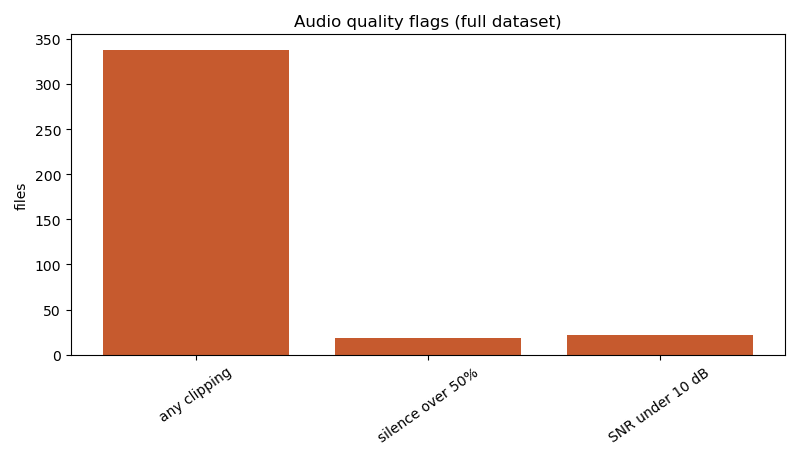

In [6]:
# Chart: quality flags, counts in the full set
labels = ["any clipping", "silence over 50%", "SNR under 10 dB"]
values = [q["clip_pct_gt0"], q["silence_pct_gt50"], q["snr_db_lt10"]]
bar(values, labels, "Audio quality flags (full dataset)", "files", "quality_flags.png", color="#c65a2e")

## 3. Transcripts

All 6,024 transcripts come from Whisper large-v3. 133 rows are flagged needs_review (2.2 percent). The flagged rows have much lower confidence than the clean rows, which is the signal the review flag is working: mean logprob minus 0.628 flagged versus minus 0.192 clean. A 20 row WER check against human references put large-v3 at 0.291 and turbo at 0.3495, so large-v3 is the model used.

In [7]:
t = eda["transcripts"]
print("transcript rows:", t["rows"])
print("needs_review:", t["needs_review"], "| clean:", t["clean"])
print("review reason tokens:", t["review_reasons_token"])
print("prompt empty on:", t["prompt_values"].get("", 0), "rows (normalized to none in preprocessing)")
print("errors:", t["error_non_empty"], "| empty text:", t["empty_text"])
print()
print("min_avg_logprob: all mean", t["min_avg_logprob"]["all"]["mean"], "| flagged mean", t["min_avg_logprob"]["flagged"]["mean"], "| clean mean", t["min_avg_logprob"]["clean"]["mean"])
print("text length: mean", t["text_length"]["words"]["mean"], "words, median", t["text_length"]["words"]["median"], ", range", t["text_length"]["words"]["min"], "to", t["text_length"]["words"]["max"])
print("WER (20 row eval): large-v3", t["wer_mean"]["whisper-large-v3"], "| turbo", t["wer_mean"]["whisper-large-v3-turbo"])
print()
print("Three real transcript rows (file, first 90 chars of text, logprob, needs_review):")
for _, r in clean.head(3).iterrows():
    print(" ", r["file"].split("\\")[-1], "|", str(r["text"])[:90], "| logprob", round(r["min_avg_logprob"], 3), "| review", bool(r["needs_review"]))

transcript rows: 6024
needs_review: 133 | clean: 5891
review reason tokens: {'hallucination_suspect': 15, 'low_confidence': 121, 'prompt_leak': 3, 'repetition': 2, 'too_short': 10}
prompt empty on: 581 rows (normalized to none in preprocessing)
errors: 0 | empty text: 0

min_avg_logprob: all mean -0.2019 | flagged mean -0.628 | clean mean -0.1922
text length: mean 15.8167 words, median 14.0 , range 2.0 to 72.0
WER (20 row eval): large-v3 0.291 | turbo 0.3495

Three real transcript rows (file, first 90 chars of text, logprob, needs_review):
  0001.m4a | لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاك | logprob -0.204 | review False
  0002.m4a | في باقة مكتوب انها 30 يوم بس كل مرة تتجدد بعد 28 يوم ده غش ولا ايه؟ | logprob -0.232 | review False
  0003.m4a | سيد الخير، أنا حدثك بقالي أسبوع دلوقتي النت أقعد في البيت، وحدثك أنت عارف ما عايش يقدر يست | logprob -0.346 | review False


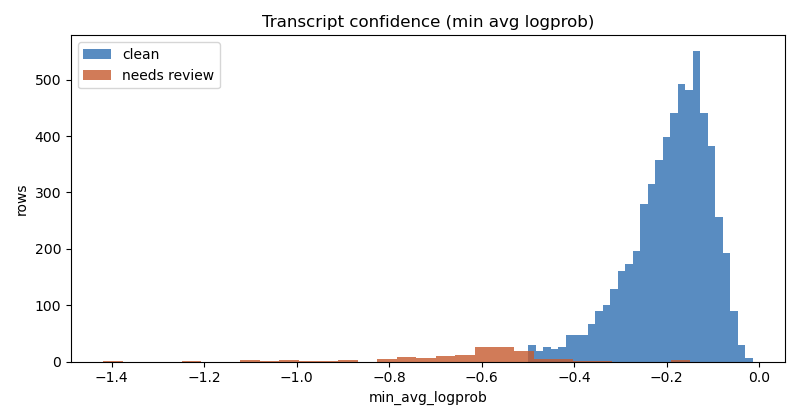

In [8]:
# Chart: logprob distribution, flagged vs clean
fig = Figure(figsize=(8, 4.2))
ax = fig.add_subplot(111)
ax.hist(clean[clean["needs_review"] == False]["min_avg_logprob"], bins=30, color="#2f6fb2", label="clean", alpha=0.8)
ax.hist(clean[clean["needs_review"] == True]["min_avg_logprob"], bins=30, color="#c65a2e", label="needs review", alpha=0.8)
ax.set_title("Transcript confidence (min avg logprob)")
ax.set_xlabel("min_avg_logprob")
ax.set_ylabel("rows")
ax.legend()
fig.tight_layout()
save_fig(fig, "logprob.png")
show("logprob.png")

## 4. Duplicates

Two kinds of duplicates exist and they are not the same. Text duplicates: 5,872 distinct normalized texts, 108 groups with more than one file, 260 rows in those groups, largest group 9 files. File duplicates: 470 files in the inventory are exact copies of another file (confirmed by source file md5, every one of the 470 has a twin), and all 470 are excluded. The train ready set has zero internal md5 duplicates and zero PCM hash duplicates.

In [9]:
d = eda["duplicates"]
print("distinct normalized texts:", d["total_text_norm_groups"])
print("groups with more than one file:", d["groups_size_gt1"])
print("rows in duplicate text groups:", d["rows_in_duplicate_groups"])
print("largest text group:", d["largest_text_norm_group"])
print("groups spanning formats:", d["duplicate_groups_spanning_multiple_formats"])
print("inventory duplicate flag true:", d["inventory_is_duplicate_flag_true"])
print()
print("Excluded verification: confirmed true duplicates by md5 twin:", excl["duplicates"]["confirmed_true_duplicates_md5_twin"], "of", excl["duplicates"]["excluded_duplicate_n"])
print("unclear duplicates (no md5 twin):", excl["duplicates"]["unclear_duplicates_no_md5_twin"])
print("train ready internal md5 duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_internal_md5_duplicates"])
print("train ready PCM hash duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_pcm_duplicates"])
print()
print("dup_text_size distribution (rows by stored value):")
for k, v in eda["transcripts"]["dup_text_size_distribution"].items():
    print(" ", k, v)
print("dup_text_size wrong on exactly 3 rows (all say 1, true value 3):")
for m in eda["transcripts"]["dup_mismatches"]:
    print(" ", m["file"].split("\\")[-1], "| stored", m["stored_dup_text_size"], "| actual", m["actual_dup_text_size"])

distinct normalized texts: 5872
groups with more than one file: 108
rows in duplicate text groups: 260
largest text group: 9
groups spanning formats: 84
inventory duplicate flag true: 470

Excluded verification: confirmed true duplicates by md5 twin: 470 of 470
unclear duplicates (no md5 twin): 0
train ready internal md5 duplicates: 0
train ready PCM hash duplicates: 0

dup_text_size distribution (rows by stored value):
  1 5764
  2 79
  3 20
  4 7
  5 1
  9 1
dup_text_size wrong on exactly 3 rows (all say 1, true value 3):
  1015.m4a | stored 1 | actual 3
  WhatsApp Audio 2025-11-30 at 11.54.59 PM (1).mp4 | stored 1 | actual 3
  AUDIO-2025-11-27-17-01-39.m4a | stored 1 | actual 3


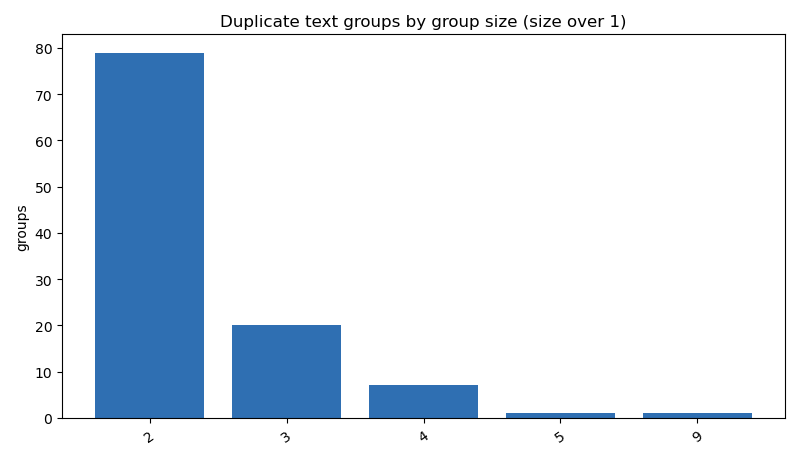

In [10]:
# Chart: duplicate text group sizes
gs = {int(k): v for k, v in eda["duplicates"]["group_size_distribution"].items() if int(k) > 1}
bar(list(gs.values()), [str(k) for k in gs.keys()], "Duplicate text groups by group size (size over 1)", "groups", "dup_groups.png")

## 5. Labels (version 1)

The train ready set of 5,881 rows was labeled from the transcript text only, using the approved taxonomy (10 categories, 3 urgency levels, 5 customer states, churn at risk or not). Hazem's 4 rows match exactly, which is the anchor for the whole labeling. The weak spots are visible here: other holds 796 rows (13.5 percent), greeting_only holds 0 rows, 417 rows are low confidence, and 219 rows could not be labeled confidently.

In [11]:
print("total labeled rows:", lab_sum["total_rows"])
print()
print("complaint_category:")
for k, v in lab_sum["complaint_category"].items():
    print(" ", k, v, "(" + str(round(100 * v / lab_sum["total_rows"], 1)) + "%)")
print()
print("complaint_urgency:", lab_sum["complaint_urgency"])
print("customer_state:", lab_sum["customer_state"])
print("churn_risk:", lab_sum["churn_risk"])
print("confidence:", lab_sum["confidence"])
print("rows not labeled confidently:", lab_sum["rows_not_labeled_confidently"])
print("Hazem 4 rows match exactly:", lab_sum["hazem_4_rows_match_exactly"])
print("calibration rows in train ready:", lab_sum["calibration_rows_in_train_ready"])
print()
print("Five real labeled rows (file, category, urgency, state, churn, confidence):")
for _, r in lab.head(5).iterrows():
    print(" ", r["file"].split("\\")[-1], "|", r["complaint_category"], "|", r["complaint_urgency"], "|", r["customer_state"], "|", r["churn_risk"], "|", r["confidence"])

total labeled rows: 5881

complaint_category:
  network_and_connectivity 978 (16.6%)
  other 796 (13.5%)
  billing_and_charges 774 (13.2%)
  balance_and_data 772 (13.1%)
  app_and_account 730 (12.4%)
  thanks_or_praise 705 (12.0%)
  no_reply_or_long_wait 468 (8.0%)
  branch_and_staff 446 (7.6%)
  cancellation_request 212 (3.6%)

complaint_urgency: {'medium': 3396, 'low': 1943, 'high': 542}
customer_state: {'frustrated': 2480, 'calm': 2335, 'satisfied': 709, 'unclear': 197, 'mad': 160}
churn_risk: {'not_at_risk': 5849, 'at_risk': 32}
confidence: {'high': 5464, 'low': 417}
rows not labeled confidently: 219
Hazem 4 rows match exactly: True
calibration rows in train ready: 90

Five real labeled rows (file, category, urgency, state, churn, confidence):
  0001.m4a | billing_and_charges | medium | calm | not_at_risk | high
  0002.m4a | balance_and_data | medium | mad | not_at_risk | high
  0003.m4a | network_and_connectivity | high | frustrated | not_at_risk | high
  0004.m4a | other | low | 

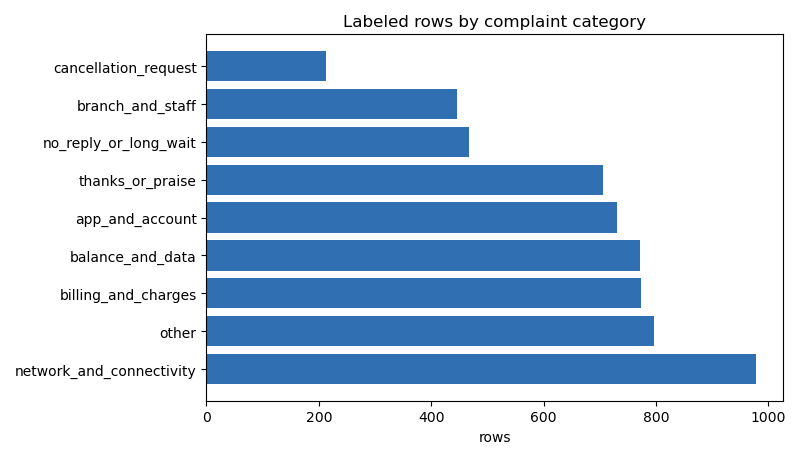

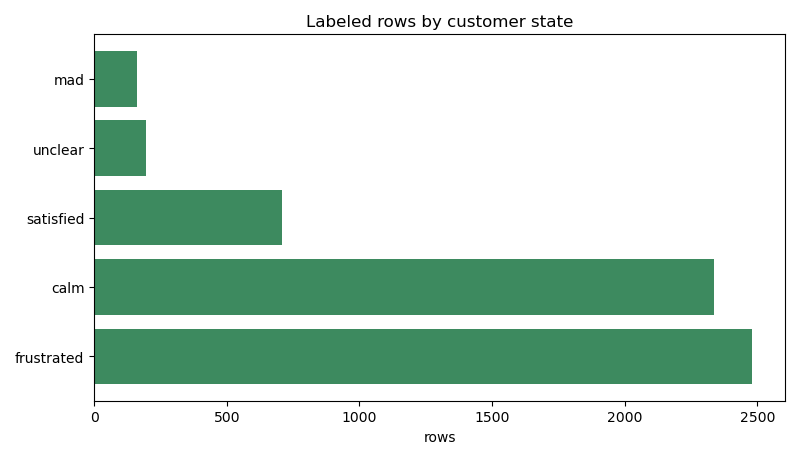

In [12]:
# Charts: category and state distributions
cat = lab_sum["complaint_category"]
bar(list(cat.values()), list(cat.keys()), "Labeled rows by complaint category", "rows", "category.png", horizontal=True)
st = lab_sum["customer_state"]
bar(list(st.values()), list(st.keys()), "Labeled rows by customer state", "rows", "state.png", color="#3d8a5f", horizontal=True)

## 6. Issues detected

The audit found 13 issues. The labeling and the three review passes added the rest. This table is the full issue list that the preprocessing and labeling notebooks work through. Each row has the issue, the measured size, and where it is handled.

In [13]:
issues = [
    ("No labels", "0 of 6,024 rows had any label column", "labeling notebook"),
    ("Other bucket too big", "796 rows, 13.5 percent, 11 themes inside", "labeling notebook, clustering"),
    ("greeting_only empty", "0 rows, every greeting is followed by a question", "labeling notebook"),
    ("Garbled transcripts", "219 rows could not be labeled confidently", "preprocessing notebook, re-transcription test"),
    ("Low confidence rows", "417 rows, mean logprob far below clean", "preprocessing notebook"),
    ("Quarantine unreviewed", "143 rows, 133 needs_review plus 10 silence", "preprocessing notebook, review pass"),
    ("Excluded, recoverable?", "498 rows, 26 recovered, rest checked", "preprocessing notebook, recovery check"),
    ("Duplicates", "470 files, all confirmed true by md5 twin", "preprocessing notebook, stay excluded"),
    ("Clipping", "320 rows in the transcribed pool, all under 1 percent", "preprocessing notebook, tolerate"),
    ("Duration drift", "2,110 rows off by over 0.01 s vs decoded PCM", "preprocessing notebook, corrected"),
    ("dup_text_size wrong", "exactly 3 rows, stored 1, true 3", "preprocessing notebook, fixed in derived file"),
    ("Long file", "one file 125.92 s, product max 60 s", "preprocessing notebook, chunked into 3"),
    ("Low SNR", "22 files under 10 dB, 18 excluded, 0 in training pool", "preprocessing notebook"),
    ("Silence", "18 files over 50 percent silence", "preprocessing notebook"),
    ("Rights and consent", "source, license, consent unconfirmed", "open, Hazem decides"),
]
df = pd.DataFrame(issues, columns=["issue", "measured size", "handled in"])
print(df.to_string(index=False))
print()
print("Themes inside the other bucket (796 rows):")
for k, v in other_themes.items():
    print(" ", k, v["row_count"], "rows | new category:", v["proposed_new_category"])
print()
print("Quarantine review decisions (143 rows):")
print(quar["decision"].value_counts().to_dict())
rc = excl["recovery_coverage"]
print("Excluded verification: recovery coverage exact, 26 of 26 recovered, 0 mismatches:", rc["recovered_n"] == 26 and len(rc["reason_mismatches_vs_disposition"]) == 0)
print("Duration drift after correction: mismatches:", excl["duration_drift"]["mismatches_corrected_vs_decoded"])

                 issue                                         measured size                                    handled in
             No labels                  0 of 6,024 rows had any label column                             labeling notebook
  Other bucket too big              796 rows, 13.5 percent, 11 themes inside                 labeling notebook, clustering
   greeting_only empty      0 rows, every greeting is followed by a question                             labeling notebook
   Garbled transcripts             219 rows could not be labeled confidently preprocessing notebook, re-transcription test
   Low confidence rows                417 rows, mean logprob far below clean                        preprocessing notebook
 Quarantine unreviewed            143 rows, 133 needs_review plus 10 silence           preprocessing notebook, review pass
Excluded, recoverable?                  498 rows, 26 recovered, rest checked        preprocessing notebook, recovery check
            Dupl

## 7. Insights

What the analysis shows, in plain words.

1. The dataset is real voicemail, not clean studio speech. Short calls (median 6.2 seconds), phone codecs, mixed formats, and a long tail of quality problems. Any model trained on it must expect noise.
2. The transcript layer is the weak layer, not the audio layer. Audio is 100 percent readable. Transcripts cover 6,024 of 6,522 files, and the 2.2 percent flagged rows carry most of the risk: their mean logprob is three times worse than clean rows.
3. Labels were the missing piece, and now they exist for the train ready set. The taxonomy fits most rows, but other at 13.5 percent is the sign the taxonomy is incomplete, and greeting_only at 0 rows is the sign one category is dead.
4. Duplicates are already solved by exclusion. All 470 are confirmed true copies, none leak into the train ready set, and the train ready set has zero internal duplicates by md5 or by decoded PCM hash.
5. Clipping is a non issue at this size. 320 rows clip, all under 1 percent of samples, and clipped rows have the same transcript confidence as clean rows (mean logprob minus 0.193 versus minus 0.192). Tolerate, do not drop.
6. The recoverable set is small and exact: 26 files. 18 low SNR by denoise, 6 clipped by declip, 1 silence trim, 1 long file chunked. Nothing else among the 498 excluded rows is recoverable.
7. The 143 quarantined rows split three ways: 62 can join training, 18 stay out (mostly Whisper video outro hallucinations), 63 wait on re-transcription.
8. The 219 garbled rows are the hardest decision. They are 3.7 percent of the train ready set. Re-transcription is the only fix that could save them; if it does not clearly improve the text, they are excluded.
9. Rights, consent, and retention are still open. Nothing in this analysis proves source, license, or consent. That decision is Hazem's alone.
10. The data type differences are the shape of the dataset, not a defect in one file. Nine formats, two sample rates (48 kHz and 44.1 kHz), mono and stereo mixed. Nothing downstream can assume one type, so every file is decoded to 16 kHz mono WAV before any model sees it.

In [14]:
# Final numbers: the dataset at a glance, before any fixing
print("DATASET AT A GLANCE (before fixing)")
print("audio files:", inv["aggregate"]["total_files"])
print("total hours:", round(inv["aggregate"]["total_duration_h"], 2))
print("transcripts:", len(clean))
print("train ready:", prep["transcripts"]["train_ready"])
print("quarantine:", prep["transcripts"]["quarantine"])
print("excluded:", prep["files"]["excluded"])
print("labeled rows:", len(lab))
print("other bucket:", lab_sum["other_rows"], "rows")
print("low confidence rows:", lab_sum["low_confidence_rows"])
print("rows not labeled confidently:", lab_sum["rows_not_labeled_confidently"])
print("recovered files awaiting transcription:", audit["issues"]["recoverable"]["total"])
print("rights and consent: OPEN, Hazem decides")
print()
print("Sample of a real labeled row with its transcript:")
r = lab.iloc[0]
t = clean[clean["file"] == r["file"]].iloc[0]
print("file:", r["file"])
print("text:", t["text"])
print("labels:", r["complaint_category"], "|", r["complaint_urgency"], "|", r["customer_state"], "|", r["churn_risk"], "| confidence", r["confidence"])

DATASET AT A GLANCE (before fixing)
audio files: 6522
total hours: 12.63
transcripts: 6024
train ready: 5881
quarantine: 143
excluded: 498
labeled rows: 5881
other bucket: 796 rows
low confidence rows: 417
rows not labeled confidently: 219
recovered files awaiting transcription: 26
rights and consent: OPEN, Hazem decides

Sample of a real labeled row with its transcript:
file: الكل ان شاء الله\0001.m4a
text: لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاكه قليل جداً
labels: billing_and_charges | medium | calm | not_at_risk | confidence high
